<a href="https://colab.research.google.com/github/Nasim-Amani/tag-recommender-agent-learning/blob/main/hands-on-levels/L3_lightgcn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Level 3: Graph (LightGCN)

**Goal:** instead of hand-made rules (Level 2 votes), let a model **learn** where to place every product and tag, so that each product ends up **close to its own tags**.

**The graph:**
- **Nodes:** products and tags
- **Edges:** product — tag, for every **training** product and its true tags (e.g. hair mask — `dry hair`)

## LightGCN as a map

Think of every product and tag as a **point on a map**. A node's **vector** is just its **position** (2 numbers here; 64 in the real model). To recommend tags for a product, pick the **tags closest to it**.

### Idea 1: everyone starts at a random position

| Node | Start position |
|---|---|
| Hair mask (product) | (0.1, 0.9) |
| Curl cream (product) | (0.8, 0.2) |
| `dry hair` (tag) | (0.7, 0.3) |
| `curly hair` (tag) | (0.2, 0.8) |

Edges: hair mask — `dry hair`, curl cream — `curly hair`.
At the start the map is wrong: the hair mask sits next to `curly hair`.

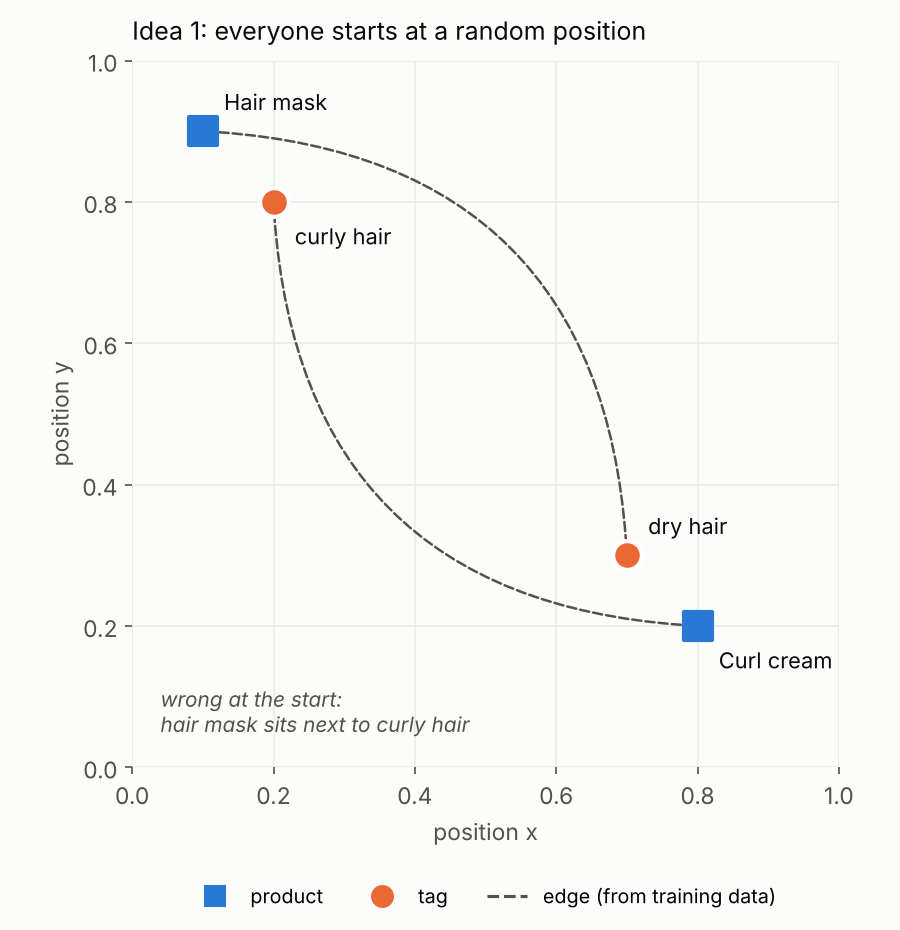

In [ ]:
#@title fig1 random start
# (figure stored in this cell's output)

### Idea 2: message passing = move toward your connections

Each node's new position = **average of its own position and its neighbors' positions**:
- Hair mask = average of (0.1, 0.9) and `dry hair` (0.7, 0.3) = **(0.4, 0.6)** → moved toward `dry hair`
- `dry hair` = average of (0.7, 0.3) and hair mask (0.1, 0.9) = **(0.4, 0.6)** → moved toward the hair mask

**Connected nodes pull each other closer.** Repeating this 3 times (3 layers) lets information travel further: hair mask → `dry hair` → another product with `dry hair`.

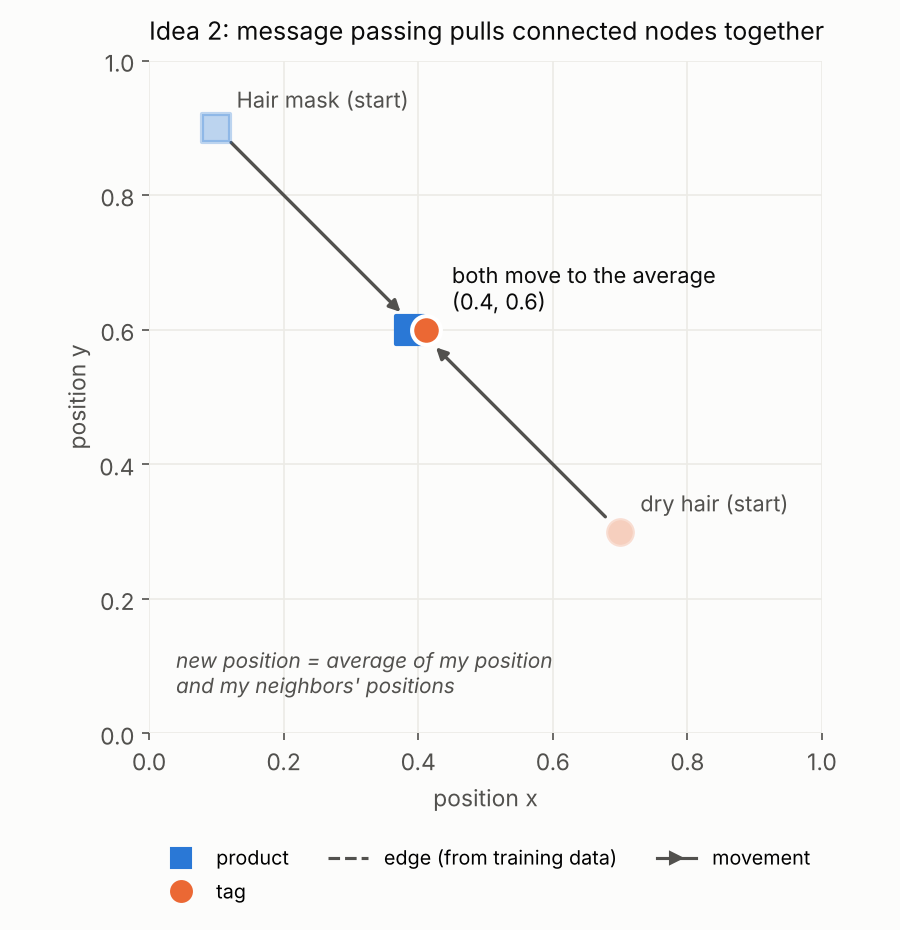

In [ ]:
#@title fig2 message passing
# (figure stored in this cell's output)

### Idea 3: training = adjust the start positions

For every training pair, the model checks one rule:

> **A product must be closer to its true tag than to a random tag.**

- Hair mask vs `dry hair` (true) → should be **close**
- Hair mask vs `nail polish` (random) → should be **far**

If the rule is broken, the model **nudges the start positions** a little (Adam). After 300 rounds, products sit near their tags. This rule is the **BPR loss**.

**Score of a (product, tag) pair** = how close the two points are (dot product: bigger = closer) → top 10 tags.

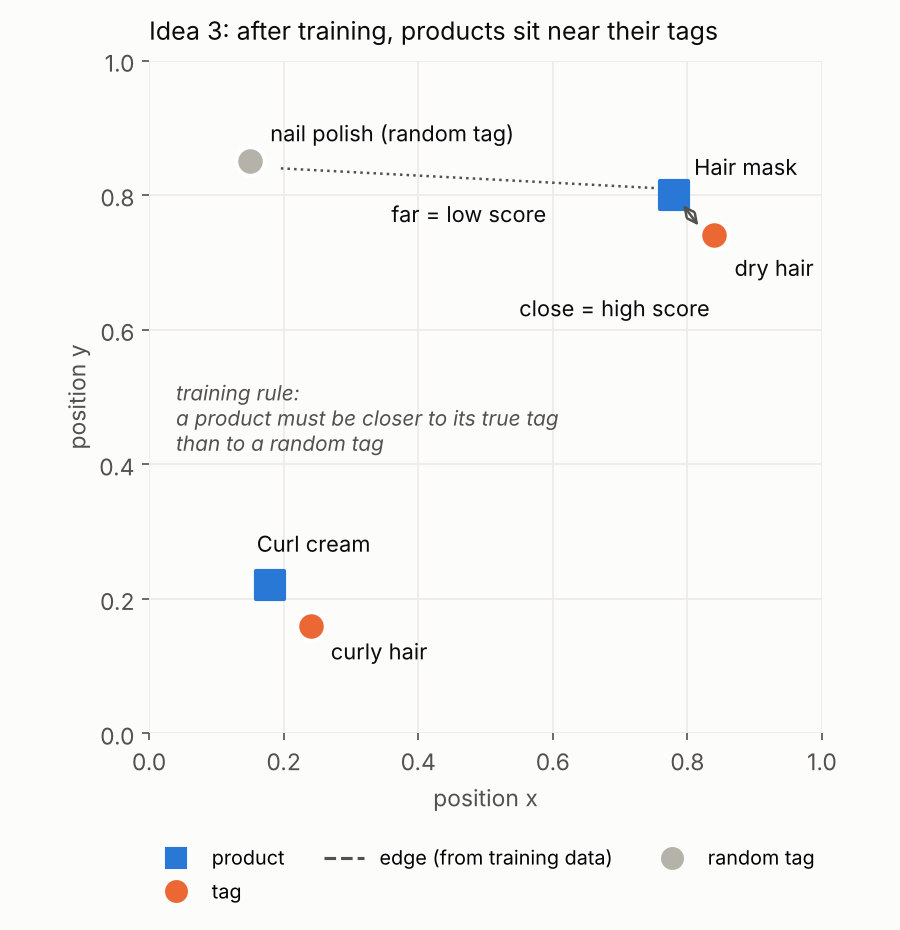

In [ ]:
#@title fig3 after training
# (figure stored in this cell's output)

## What to expect (3a and 3b)

**3a, plain graph:** a **new** shampoo has **no tags → no edges → nothing pulls it anywhere**. It stays at its **random start position**, so its closest tags are random: it should do about as badly as **Random**.

**3b, + text neighbors:** add edges new shampoo — similar old shampoos (by text similarity). Message passing then pulls it toward those shampoos, which sit near `dry hair`.

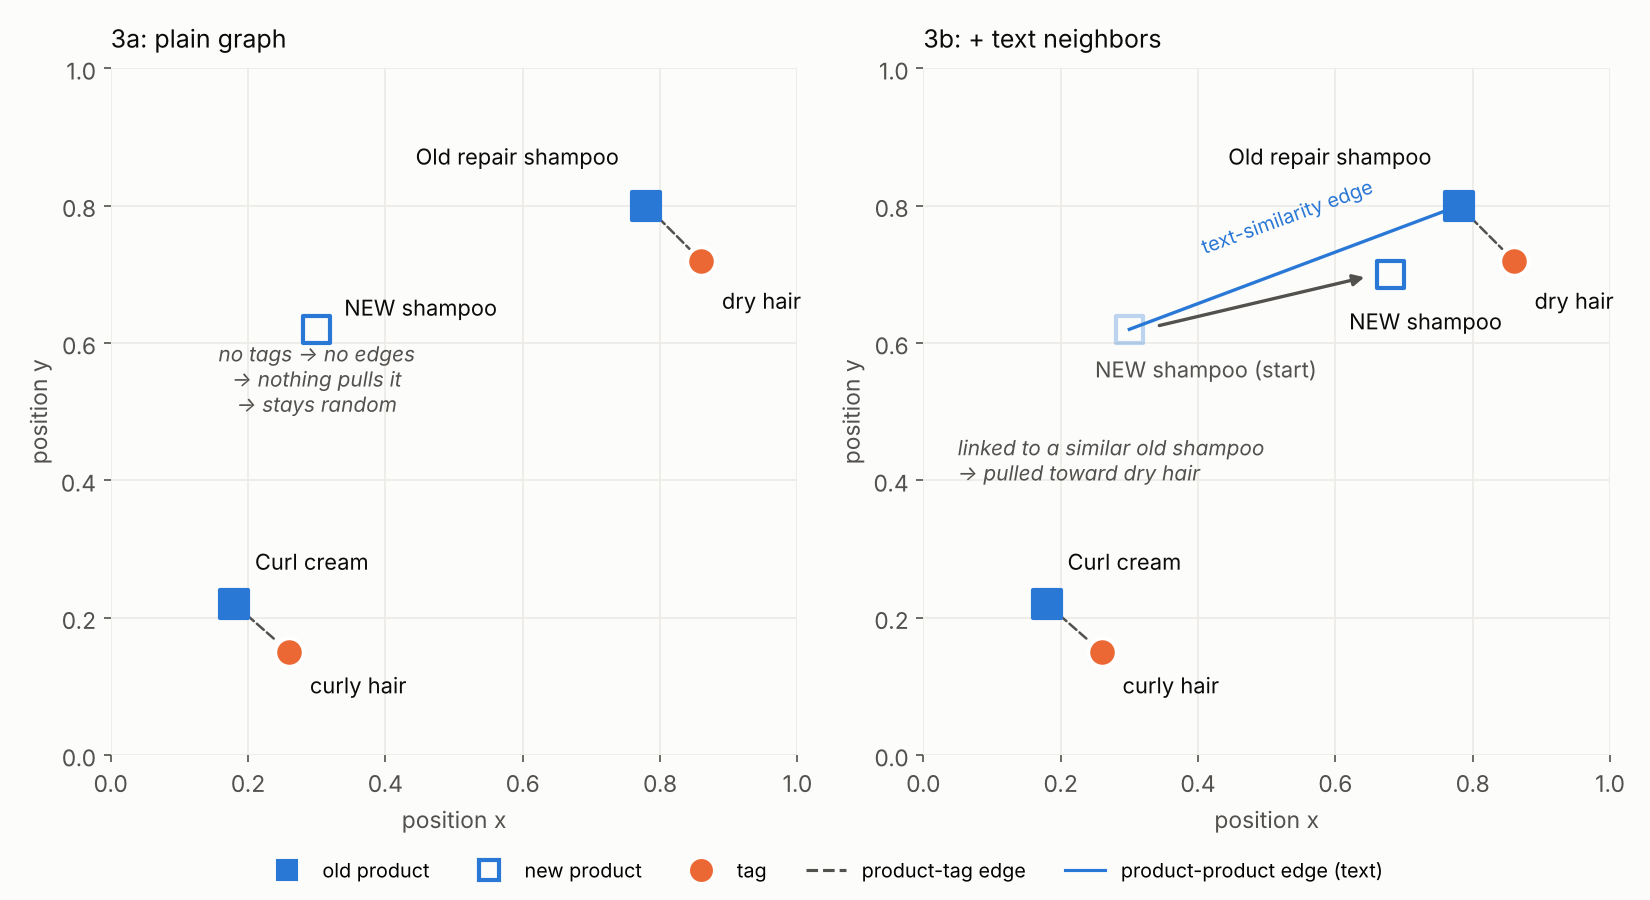

In [ ]:
#@title fig4 cold start
# (figure stored in this cell's output)

setup, the same as Level 1 (data, tags, split)

In [1]:
import json, gzip, os, urllib.request
from collections import Counter
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

# 1) Download the two files (only the first time)
base = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw"
for url, name in [(f"{base}/meta_categories/meta_All_Beauty.jsonl.gz", "meta.jsonl.gz"),
                  (f"{base}/review_categories/All_Beauty.jsonl.gz", "reviews.jsonl.gz")]:
    if not os.path.exists(name):
        urllib.request.urlretrieve(url, name)

# 2) Read the first 2,000 products
products = []
for line in gzip.open("meta.jsonl.gz", "rt"):
    products.append(json.loads(line))
    if len(products) == 2000:
        break

# 3) Reviews and first-review time of those products
reviews = {p["parent_asin"]: [] for p in products}
first_time = {}
for line in gzip.open("reviews.jsonl.gz", "rt"):
    r = json.loads(line)
    a = r["parent_asin"]
    if a in reviews:
        reviews[a].append(r["text"])
        first_time[a] = min(first_time.get(a, r["timestamp"]), r["timestamp"])

# 4) Tags = values of seller attributes, minus identifiers and junk keys
SKIP = {"Brand", "Manufacturer", "UPC", "Product Dimensions", "Item model number",
        "Date First Available", "Item Weight", "Package Dimensions",
        "Is Discontinued By Manufacturer", "Unit Count", "Number of Items",
        "Age Range (Description)", "Mounting Type", "Installation Type",
        "Package Information", "Extension Length"}

def all_tags_of(p):
    tags = []
    for key, value in p["details"].items():
        if key in SKIP or not isinstance(value, str):
            continue
        for v in value.split(","):                 # "Oily, Dry" -> two tags
            v = v.strip().lower()
            if v and v != "all":                   # "suits everyone" is not a tag
                tags.append(f"{key}: {v}")
    return tags

counts = Counter(t for p in products for t in all_tags_of(p))
candidate_tags = sorted(t for t, c in counts.items() if c >= 20)   # tags on >= 20 products
products = [p for p in products if set(all_tags_of(p)) & set(candidate_tags)]
n, m = len(products), len(candidate_tags)

# 5) Answer key Y: Y[k, j] = 1 if product k has tag j
Y = np.array([[t in all_tags_of(p) for t in candidate_tags] for p in products], dtype=float)

# 6) Split by time: oldest 70% train, next 15% validation, newest 15% test (= new products)
t = np.array([first_time.get(p["parent_asin"], np.inf) for p in products])
order = np.argsort(t)
train_idx = order[: int(0.70 * n)]
val_idx   = order[int(0.70 * n): int(0.85 * n)]
test_idx  = order[int(0.85 * n):]
print(n, "products |", m, "tags |", len(train_idx), "train /", len(val_idx), "val /", len(test_idx), "test")

1057 products | 35 tags | 739 train / 159 val / 159 test


metric, BERT vectors and the Level 1 baselines (for comparison)

In [2]:
def evaluate(scores, products_idx, K=10):
    """scores: (products, tags), higher = more likely -> Precision@K, Recall@K, NDCG@K."""
    truth = Y[products_idx]
    top = np.argsort(-scores, axis=1)[:, :K]                    # the K best tags per product
    hits = np.take_along_axis(truth, top, axis=1)               # 1 where a recommended tag is correct
    n_true = truth.sum(axis=1)
    discount = 1 / np.log2(np.arange(2, K + 2))                 # position 1 counts most
    ideal = np.array([discount[:int(min(nt, K))].sum() for nt in n_true])
    return {"Precision@10": (hits.sum(axis=1) / K).mean(),
            "Recall@10":    (hits.sum(axis=1) / n_true).mean(),
            "NDCG@10":      ((hits * discount).sum(axis=1) / ideal).mean()}

# BERT vectors for products and tags
encoder = SentenceTransformer("all-MiniLM-L6-v2")
texts = [p["title"] + " " + " ".join(p["features"] + p["description"]) for p in products]
Z_prod = encoder.encode(texts, normalize_embeddings=True)          # (n, 384)
Z_tag  = encoder.encode(candidate_tags, normalize_embeddings=True) # (m, 384)

# Level 1 baselines
results = {}
rng = np.random.default_rng(0)
results["Random"] = evaluate(rng.random((len(test_idx), m)), test_idx)
results["Popularity"] = evaluate(np.tile(Y[train_idx].sum(axis=0), (len(test_idx), 1)), test_idx)
results["Text similarity"] = evaluate(Z_prod[test_idx] @ Z_tag.T, test_idx)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (3 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [3]:

# ===== Level 2: borrow tags from the most similar TRAINING products =====
K_NEIGHBORS = 5

# 1) Similarity of every test product to every training product (BERT vectors from Level 1)
sims = Z_prod[test_idx] @ Z_prod[train_idx].T            # (test products, train products)

# 2) The 5 most similar training products for each test product
top = np.argsort(-sims, axis=1)[:, :K_NEIGHBORS]          # positions inside train_idx
neighbors = train_idx[top]                                # real product numbers, (test, 5)
neighbor_sims = np.take_along_axis(sims, top, axis=1)     # their similarity scores, (test, 5)

# 3a) Vote: each tag's score = number of neighbors that have it
#     Y[neighbors] is (test, 5, tags) -> sum over the 5 neighbors -> (test, tags)
votes = Y[neighbors].sum(axis=1)
results["Neighbors (vote)"] = evaluate(votes, test_idx)

# 3b) Weighted vote: closer neighbors count more (each neighbor's tags x its similarity)
weighted = (neighbor_sims[:, :, None] * Y[neighbors]).sum(axis=1)
results["Neighbors (weighted)"] = evaluate(weighted, test_idx)

table = pd.DataFrame(results).T.round(3)
table

,Precision@10,Recall@10,NDCG@10
Random,0.048,0.241,0.133
Popularity,0.116,0.573,0.340
Text similarity,0.123,0.651,0.484
Neighbors (vote),0.148,0.765,0.630
Neighbors (weighted),0.148,0.765,0.636


graph builder, model and training

In [4]:
import torch
import torch.nn.functional as F

# Use the GPU if Colab has one, otherwise the CPU (this small graph is fast on CPU too)
device = "cpu"

# ------------------------------------------------------------------
# Node numbering: one number per node in the graph
#   products = 0 .. n-1        (e.g. product 5 is node 5)
#   tags     = n .. n+m-1      (e.g. tag 0 is node n, tag 1 is node n+1, ...)
# ------------------------------------------------------------------
N_NODES = n + m


def build_graph(extra_pairs=None):
    """Build the graph's EDGES (the lines on the map). They come from the DATA, not chance.
    - product <-> tag edges: every TRAINING product with each of its true tags
    - extra_pairs (used in 3b): product <-> product edges from text similarity
    Returns the graph as a normalized 'adjacency matrix' A:
    A[i, j] > 0 means node i receives information from node j."""

    # 1) All (train product, true tag) pairs -> one edge each
    rows, cols = np.where(Y[train_idx] == 1)        # rows = position in train_idx, cols = tag number
    prod = train_idx[rows]                          # real product node numbers
    tag = n + cols                                  # tag node numbers (tags start at n)

    # 2) Edges go both ways: product -> tag AND tag -> product
    #    (so information flows in both directions during message passing)
    src, dst = [prod, tag], [tag, prod]             # src = sender, dst = receiver

    # 3) (3b only) add product <-> product edges, also both ways
    if extra_pairs is not None:
        a, b = extra_pairs
        src += [a, b]; dst += [b, a]
    src, dst = np.concatenate(src), np.concatenate(dst)

    # 4) Normalize: a node with many edges (e.g. a popular tag on 500 products) would
    #    otherwise get a huge sum of messages. Each edge's weight = 1 / sqrt(deg_sender * deg_receiver)
    deg = np.bincount(src, minlength=N_NODES).astype(float)       # number of edges per node
    w = 1 / np.sqrt(deg[src] * deg[dst])

    # 5) Store A as a SPARSE matrix: only the edges are stored, not the millions of zeros
    A = torch.sparse_coo_tensor(
        torch.tensor(np.vstack([dst, src])),        # positions: (receiver, sender)
        torch.tensor(w, dtype=torch.float32),       # values: the edge weights
        (N_NODES, N_NODES)).coalesce()
    return A.to(device)


class LightGCN(torch.nn.Module):
    """The model. Its ONLY learnable part is the start position (vector) of every node."""

    def __init__(self, n_nodes, dim=64, n_layers=3):
        super().__init__()
        # Idea 1: every node gets a vector of 64 numbers = its position on the map
        self.emb = torch.nn.Embedding(n_nodes, dim)
        torch.nn.init.normal_(self.emb.weight, std=0.1)    # random start positions
        self.n_layers = n_layers

    def forward(self, A):
        # Idea 2: message passing = each node moves toward its connections
        x = self.emb.weight                                # layer 0: the start positions
        layers = [x]
        for _ in range(self.n_layers):                     # 3 rounds of mixing
            x = torch.sparse.mm(A, x)                      # each node = weighted mix of its neighbors
            layers.append(x)
        # Final position = average of layer 0, 1, 2, 3
        # (keeps some of the node's own position + what it learned from 1, 2, 3 steps away)
        return torch.stack(layers).mean(dim=0)             # (N_NODES, 64)


def train_lightgcn(A, epochs=300, verbose=True):
    """Idea 3: adjust the start positions so each product is closer to its TRUE tags
    than to RANDOM tags (the BPR rule). Returns the final positions of all nodes."""
    torch.manual_seed(0); np.random.seed(0)                # same result every run
    model = LightGCN(N_NODES).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-4)   # Adam nudges the positions

    # The training examples: every (train product, true tag) pair
    rows, cols = np.where(Y[train_idx] == 1)
    pos_prod = torch.tensor(train_idx[rows], device=device)      # products
    pos_tag = torch.tensor(n + cols, device=device)              # their true tags

    for epoch in range(1, epochs + 1):
        # For each pair, pick one RANDOM tag to compare against (e.g. "nail polish")
        neg_tag = torch.randint(n, n + m, pos_tag.shape, device=device)

        E = model(A)                                             # current final positions

        # Score = dot product = how close two points are (bigger = closer)
        s_pos = (E[pos_prod] * E[pos_tag]).sum(dim=1)            # product vs TRUE tag
        s_neg = (E[pos_prod] * E[neg_tag]).sum(dim=1)            # product vs RANDOM tag

        # BPR loss: small when s_pos is much bigger than s_neg (rule respected),
        #           large when the random tag is as close as the true one (rule broken)
        loss = -F.logsigmoid(s_pos - s_neg).mean()

        # Adam: compute how to move every start position to reduce the loss, then move it
        opt.zero_grad(); loss.backward(); opt.step()

        # Every 50 epochs: check progress on VALIDATION products (not used for training)
        if verbose and epoch % 50 == 0:
            with torch.no_grad():                                # just measuring, no learning
                E = model(A)
                val = evaluate((E[val_idx] @ E[n:].T).cpu().numpy(), val_idx)["NDCG@10"]
            print(f"epoch {epoch}: loss {loss.item():.4f}, validation NDCG@10 {val:.3f}")

    # After training: the final positions of all nodes
    with torch.no_grad():
        E = model(A)
    return E


def lightgcn_scores(E, idx):
    """Score every tag for the products in idx = how close each tag is to each product.
    E[idx]: product positions (products, 64);  E[n:]: tag positions (tags, 64)
    Result: (products, tags) score table -> evaluate() keeps the top 10 per product."""
    return (E[idx] @ E[n:].T).cpu().numpy()

3a, the plain graph

In [5]:
A_plain = build_graph()
E_plain = train_lightgcn(A_plain)
results["LightGCN (plain)"] = evaluate(lightgcn_scores(E_plain, test_idx), test_idx)
pd.DataFrame(results).T.round(3)

/tmp/ipykernel_10795/4004397956.py:43: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  A = torch.sparse_coo_tensor(


epoch 50: loss 0.1060, validation NDCG@10 0.123
epoch 100: loss 0.0882, validation NDCG@10 0.167
epoch 150: loss 0.0829, validation NDCG@10 0.157
epoch 200: loss 0.0866, validation NDCG@10 0.212
epoch 250: loss 0.0752, validation NDCG@10 0.182
epoch 300: loss 0.0739, validation NDCG@10 0.168


,Precision@10,Recall@10,NDCG@10
Random,0.048,0.241,0.133
Popularity,0.116,0.573,0.340
Text similarity,0.123,0.651,0.484
Neighbors (vote),0.148,0.765,0.630
Neighbors (weighted),0.148,0.765,0.636
LightGCN (plain),0.065,0.361,0.203


## 3b: Connect new products through text

**The fix:** add **product — product** edges: link every product (old **and** new) to its 5 most similar **training** products, by text similarity (the same neighbors as Level 2).

Now a new shampoo is linked to old repair shampoos, which are linked to `dry hair`. Message passing carries that information to the new shampoo:

    new shampoo — old repair shampoo — dry hair

This is the graph version of Level 2: instead of counting votes by hand, the model **learns** how to use the neighbors.

3b, the graph with text neighbors

In [6]:
# Every product -> its 5 most similar TRAINING products (never itself)
sims_all = Z_prod @ Z_prod[train_idx].T                  # (all products, train products)
sims_all[train_idx, np.arange(len(train_idx))] = -np.inf # a train product is not its own neighbor
top5 = np.argsort(-sims_all, axis=1)[:, :5]
pairs = (np.repeat(np.arange(n), 5), train_idx[top5].ravel())   # (product, neighbor) pairs

A_text = build_graph(extra_pairs=pairs)
E_text = train_lightgcn(A_text)
results["LightGCN + text neighbors"] = evaluate(lightgcn_scores(E_text, test_idx), test_idx)
pd.DataFrame(results).T.round(3)

epoch 50: loss 0.1813, validation NDCG@10 0.722
epoch 100: loss 0.1516, validation NDCG@10 0.730
epoch 150: loss 0.1477, validation NDCG@10 0.730
epoch 200: loss 0.1394, validation NDCG@10 0.736
epoch 250: loss 0.1266, validation NDCG@10 0.732
epoch 300: loss 0.1299, validation NDCG@10 0.735


,Precision@10,Recall@10,NDCG@10
Random,0.048,0.241,0.133
Popularity,0.116,0.573,0.340
Text similarity,0.123,0.651,0.484
Neighbors (vote),0.148,0.765,0.630
Neighbors (weighted),0.148,0.765,0.636
LightGCN (plain),0.065,0.361,0.203
LightGCN + text neighbors,0.173,0.901,0.666




**Goal:** check whether a **learned** graph model (LightGCN) beats the simple neighbor vote of Level 2 on new products.

| Method | Precision@10 | Recall@10 | NDCG@10 |
|---|---|---|---|
| Neighbors (weighted), Level 2 | 0.148 | 0.765 | 0.636 |
| LightGCN (plain), 3a | 0.065 | 0.361 | 0.203 |
| **LightGCN + text neighbors, 3b** | **0.173** | **0.901** | **0.666** |

**1. Plain graph fails for new products (3a).** NDCG 0.203 is close to Random: new products have **no edges**, so nothing reaches them. This is the cold-start problem, now measured.

**2. Text edges fix it (3b): 0.203 → 0.666.** Linking each product to its 5 most similar products **by text** connects new products to the graph. The text is what makes the graph usable for new products.

**3. Learning beats simple voting, mostly in Recall.**
- **Recall: 0.765 → 0.901**: in the top 10 it now finds **90%** of true tags (vs 77%). Message passing over 3 layers reaches tags that the 5 direct neighbors don't have.
- **NDCG: 0.636 → 0.666** (+0.03): the ordering improves only a little.

**4. Training converged early.** Validation NDCG is already **0.72 at epoch 50** and stays at 0.73–0.74 after that, so 300 epochs are more than needed (~100 would do).

**Caution:** this is **one run** with a small test set. The NDCG gain over Level 2 (+0.03) is small and could change with another random seed; the Recall gain (+0.14) is large enough to be trusted.

**New bar for the next level:** NDCG@10 = **0.666**, Recall@10 = **0.901**.